# Modelos recurrentes 

Se comparan LSTM y GRU multi-salida y encoder-decoder con
covariables de calendario. Los modelos se entrenaron en Google Colab
con GPU Tesla T4, usando L=168 y H=24.

La evaluación de prueba utiliza el protocolo compartido:
92 orígenes diarios entre octubre y diciembre de 2014.

In [1]:
print("El kernel responde", flush=True)

El kernel responde


In [3]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

import common as C

MODELOS = [
    "lstm_multi",
    "gru_multi",
    "seq2seq_lstm",
    "seq2seq_gru",
]

necesarios = [
    C.PANEL_PATH,
    *[C.PRED_DIR / f"{modelo}.parquet" for modelo in MODELOS],
]

faltantes = [str(p) for p in necesarios if not p.exists()]

if faltantes:
    raise FileNotFoundError(
        "Faltan estos archivos:\n" + "\n".join(faltantes)
    )

print("Panel y cuatro archivos de pronósticos encontrados.")

Panel y cuatro archivos de pronósticos encontrados.


In [4]:
panel = C.load_panel()
evaluaciones = {}
filas = []

for modelo in MODELOS:
    resultado = C.evaluate(
        C.PRED_DIR / f"{modelo}.parquet",
        panel,
    )
    evaluaciones[modelo] = resultado

    filas.append({
        "modelo": modelo,
        **resultado["global"],
        "MASE_22_28dic": resultado["xmas"]["MASE"],
        "pronosticos": resultado["n"],
    })

tabla = (
    pd.DataFrame(filas)
    .set_index("modelo")
    .sort_values("MASE")
)

display(tabla.round(4))

tabla.to_csv(C.ROOT / "results" / "metricas_recurrentes_B.csv")

print("Tabla guardada en results/metricas_recurrentes_B.csv")

,MAE,RMSE,WAPE,MAPE,MAPE_n_excluidos,MASE,MASE_22_28dic,pronosticos
modelo,,,,,,,,
seq2seq_lstm,40.5994,192.3321,0.0753,0.1146,3018,0.9585,1.6737,220800
seq2seq_gru,41.2605,199.5308,0.0765,0.1148,3018,0.9589,1.8300,220800
gru_multi,42.3790,183.4044,0.0786,0.1123,3018,1.0228,1.7958,220800
lstm_multi,43.0896,192.3069,0.0799,0.1232,3018,1.0231,1.7869,220800


Tabla guardada en results/metricas_recurrentes_B.csv


In [5]:
display(
    tabla[
        ["MAE", "RMSE", "WAPE", "MAPE", "MASE", "MASE_22_28dic", "pronosticos"]
    ].round(4)
)

,MAE,RMSE,WAPE,MAPE,MASE,MASE_22_28dic,pronosticos
modelo,,,,,,,
seq2seq_lstm,40.5994,192.3321,0.0753,0.1146,0.9585,1.6737,220800
seq2seq_gru,41.2605,199.5308,0.0765,0.1148,0.9589,1.8300,220800
gru_multi,42.3790,183.4044,0.0786,0.1123,1.0228,1.7958,220800
lstm_multi,43.0896,192.3069,0.0799,0.1232,1.0231,1.7869,220800


## Resultados en prueba

Los modelos encoder-decoder obtuvieron menor MASE que los modelos
multi-salida. Seq2seq LSTM alcanzó el menor MASE (0.9585), seguido
muy de cerca por seq2seq GRU (0.9589). Sin embargo, GRU multi-salida
obtuvo el menor RMSE, por lo que el orden depende de la métrica.

Durante la semana del 22 al 28 de diciembre, el MASE aumentó en los
cuatro modelos. La selección para los siguientes experimentos se
mantiene basada en validación, donde ganó seq2seq GRU.

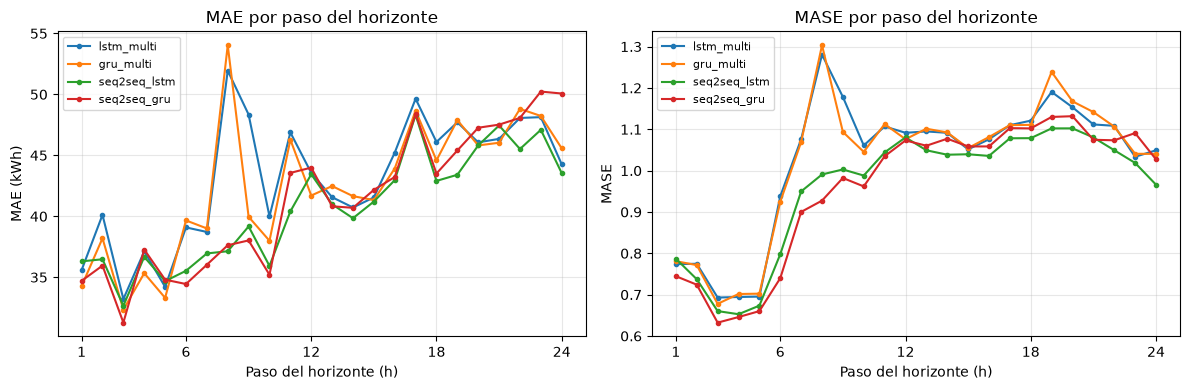

In [6]:
fig_dir = C.ROOT / "figs"
fig_dir.mkdir(exist_ok=True)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

for modelo in MODELOS:
    por_h = evaluaciones[modelo]["by_h"]

    axs[0].plot(
        por_h.index, por_h["MAE"],
        marker="o", markersize=3, label=modelo,
    )
    axs[1].plot(
        por_h.index, por_h["MASE"],
        marker="o", markersize=3, label=modelo,
    )

for ax, metrica in zip(axs, ["MAE", "MASE"]):
    ax.set_xlabel("Paso del horizonte (h)")
    ax.set_ylabel("MAE (kWh)" if metrica == "MAE" else "MASE")
    ax.set_title(f"{metrica} por paso del horizonte")
    ax.set_xticks([1, 6, 12, 18, 24])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(fig_dir / "recurrentes_error_horizonte_B.png", dpi=150)
plt.show()

Los modelos multi-salida presentan un pico de error alrededor de
h=9 (08:00), que los encoder-decoder reducen.
En los últimos pasos, seq2seq LSTM mantiene errores 
bajos, mientras que seq2seq GRU aumenta su MAE.

El error no crece de forma continua con el horizonte. Como todos
los pronósticos comienzan a medianoche, el paso del horizonte
también identifica una hora del día. Esta gráfica no permite
separar ambos efectos.

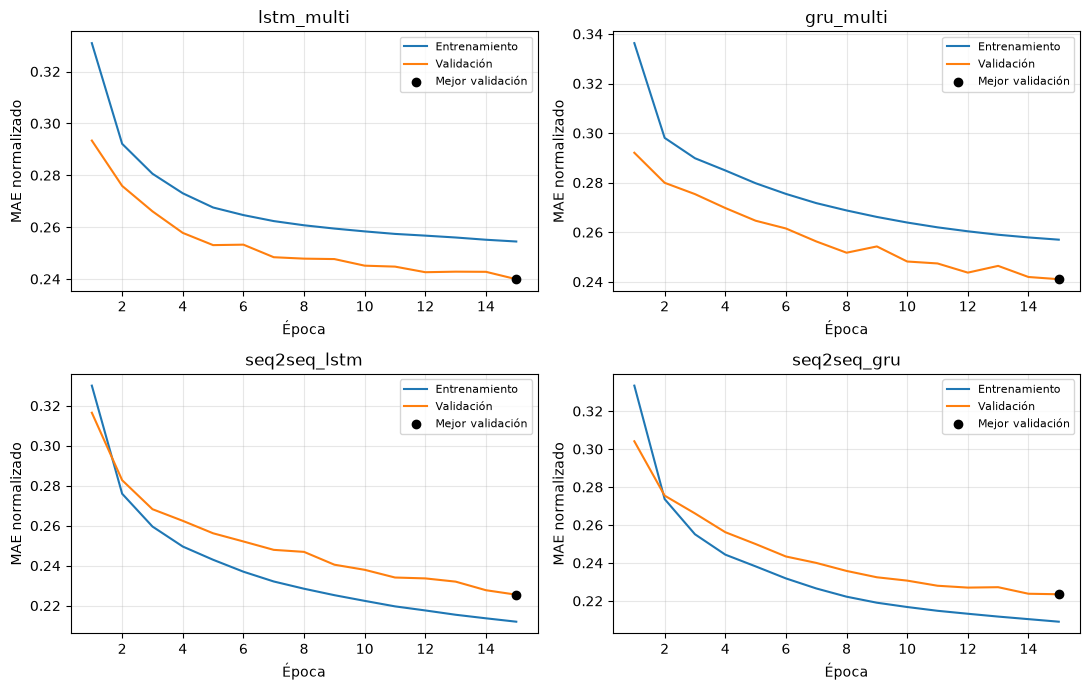

In [7]:
logs = pd.read_csv(C.ROOT / "results" / "iteraciones_B.csv")

fig, axs = plt.subplots(2, 2, figsize=(11, 7))

for ax, modelo in zip(axs.flat, MODELOS):
    datos_modelo = (
        logs[logs["modelo"] == modelo]
        .sort_values("epoca")
    )

    if datos_modelo.empty:
        raise ValueError(f"No hay logs para {modelo}")

    ax.plot(
        datos_modelo["epoca"],
        datos_modelo["train_loss"],
        label="Entrenamiento",
    )
    ax.plot(
        datos_modelo["epoca"],
        datos_modelo["val_loss"],
        label="Validación",
    )

    mejor = datos_modelo.loc[datos_modelo["val_loss"].idxmin()]
    ax.scatter(
        mejor["epoca"], mejor["val_loss"],
        color="black", zorder=3, label="Mejor validación",
    )

    ax.set_title(modelo)
    ax.set_xlabel("Época")
    ax.set_ylabel("MAE normalizado")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(fig_dir / "curvas_perdida_recurrentes_B.png", dpi=150)
plt.show()

## Análisis de las curvas de pérdida

Los cuatro modelos redujeron sus pérdidas de entrenamiento y
validación durante las 15 épocas. No se observa un aumento sostenido
de la pérdida de validación que indique sobreajuste.

Todos alcanzaron su menor pérdida de validación en la última época,
por lo que el entrenamiento terminó por el límite configurado y no
por early stopping. En futuras iteraciones conviene ampliar ese
límite y mantener la selección basada únicamente en validación.

Los encoder-decoder consiguieron menores pérdidas de validación
que los modelos multi-salida. Seq2seq GRU obtuvo el menor MASE de
validación.